In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [4]:
Combined_final = pd.read_csv('Final_cleanedDataset.csv')
len(Combined_final)
Combined_final.head()

,Job_Title,Work_mode,Posting_date,Skills,Country,date
0,AI Engineer,Remote,2024-06-01,Deep Learning,Canada,2024-06-01
1,Data Engineer,On-site,2024-11-01,"Python, Cloud",United States,2024-11-01
2,AI Engineer,Hybrid,2024-03-01,Cloud,Germany,2024-03-01
3,Data Scientist,On-site,2024-03-01,"Python, SQL, Machine Learning, Cloud",Canada,2024-03-01
4,Data Scientist,Remote,2024-12-01,"SQL, Deep Learning",Singapore,2024-12-01


In [5]:
#Making sure that it is in calendar form 
Combined_final['Posting_date'] = pd.to_datetime(Combined_final['Posting_date'])

ts_Combined_final = (
    Combined_final.set_index('Posting_date')
    .resample('MS')  #months will have another one with quarter
    .size()
    .rename('total_postings')
    .to_frame()
)

#incase there is any missing data
ts_Combined_final['total_postings'] = ts_Combined_final['total_postings'].fillna(0)
print(f"Total time series length: {len(ts_Combined_final)} months")

Total time series length: 65 months


In [6]:
# Splitting the data into 80% test and 20% training
data_split= int(len(ts_Combined_final) * 0.80)

train = ts_Combined_final.iloc[:data_split]
test = ts_Combined_final.iloc[data_split:]

y_train = train['total_postings']
y_test = test['total_postings']

print(f"Training observations (80%): {len(train)} months ({train.index[0].strftime('%Y-%m')} to {train.index[-1].strftime('%Y-%m')})")
print(f"Testing observations  (20%): {len(test)} months ({test.index[0].strftime('%Y-%m')} to {test.index[-1].strftime('%Y-%m')})")

Training observations (80%): 52 months (2021-01 to 2025-04)
Testing observations  (20%): 13 months (2025-05 to 2026-05)


In [9]:
all_train_data = ts_Combined_final['total_postings']

p,d,q = 1,1,0
P,D,Q,s = 1,1,0,12

sarimax = SARIMAX(
    endog=y_train,
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
    enforce_stationarity=True,
    enforce_invertibility=True
)

sarimax_result = sarimax.fit(disp=False)
print(sarimax_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                     total_postings   No. Observations:                   52
Model:             SARIMAX(1, 1, 0)x(1, 1, 0, 12)   Log Likelihood                -263.457
Date:                            Tue, 20 Oct 2026   AIC                            532.914
Time:                                    11:12:23   BIC                            537.905
Sample:                                01-01-2021   HQIC                           534.704
                                     - 04-01-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1959      0.184     -1.066      0.286      -0.556       0.164
ar.S.L12      -0.8135      0.076   

In [11]:

forecast_future = sarimax_result.get_forecast(steps=len(test))
forecast_mean = forecast_future.predicted_mean
conf_int = forecast_future.conf_int(alpha=0.05)

In [12]:


Lowest = (forecast_mean * 0.4).round()

future_forecast_df = pd.DataFrame({
    'Actual_Postings': y_test,
    'Forecasted_Postings': forecast_mean.round(),
    'Lower_95_CI': np.maximum(conf_int.iloc[:, 0].round(), Lowest),  # postings can't be negative
    'Upper_95_CI': conf_int.iloc[:, 1].round()
}, index=forecast_mean.index)

print("First 12 months of future forecast:")
future_forecast_df.head(12)


rmse = np.sqrt(np.mean((future_forecast_df['Actual_Postings'] - future_forecast_df['Forecasted_Postings']) ** 2))
mape = np.mean(np.abs((future_forecast_df['Actual_Postings'] - future_forecast_df['Forecasted_Postings']) / future_forecast_df['Actual_Postings'])) * 100


print("20% of the data(Testing\n")
print(future_forecast_df)
print(f"\nTest RMSE: {rmse:.2f} postings")
print(f"Test MAPE: {mape:.2f}%")


First 12 months of future forecast:
20% of the data(Testing

            Actual_Postings  Forecasted_Postings  Lower_95_CI  Upper_95_CI
2025-05-01              826                683.0        326.0       1039.0
2025-06-01              900                781.0        324.0       1238.0
2025-07-01              882                758.0        303.0       1305.0
2025-08-01             1054                905.0        362.0       1527.0
2025-09-01             1043                757.0        303.0       1448.0
2025-10-01             1355                831.0        332.0       1583.0
2025-11-01             1407                809.0        324.0       1618.0
2025-12-01             1665                697.0        279.0       1558.0
2026-01-01              274                703.0        281.0       1615.0
2026-02-01              305                624.0        250.0       1584.0
2026-03-01              468                649.0        260.0       1654.0
2026-04-01              647            

In [13]:
# fitting the complete sarimax
y_full = ts_Combined_final['total_postings']

final_model_sarimax = SARIMAX(
    endog=y_full,
    order=(1, 1, 0),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=True,
    enforce_invertibility=True
)
final_result = final_model_sarimax.fit(disp=False)

#forecast forward 2 years (24 months)
forecast_time = 24
future_forecast_obj = final_result.get_forecast(steps=forecast_time)
future_forecast_mean = future_forecast_obj.predicted_mean
future_conf_int = future_forecast_obj.conf_int(alpha=0.05)

# Build 2-year forecast dataframe
Lowest = (future_forecast_mean * 0.4).round()

two_year_forecast_sarimax = pd.DataFrame({
    'Forecasted_Postings': future_forecast_mean.round(),
    'Lower_95_CI': np.maximum(future_conf_int.iloc[:, 0].round(), Lowest), 
    'Upper_95_CI': future_conf_int.iloc[:, 1].round()
}, index=future_forecast_mean.index)

print("\n2-Year Future Forecast (24 Months Ahead)\n")
print(two_year_forecast_sarimax)


2-Year Future Forecast (24 Months Ahead)

            Forecasted_Postings  Lower_95_CI  Upper_95_CI
2026-06-01                924.0        400.0       1449.0
2026-07-01                888.0        355.0       1559.0
2026-08-01                992.0        397.0       1794.0
2026-09-01               1123.0        449.0       2035.0
2026-10-01               1147.0        459.0       2158.0
2026-11-01               1276.0        510.0       2377.0
2026-12-01               1170.0        468.0       2354.0
2027-01-01               1271.0        508.0       2533.0
2027-02-01               1209.0        484.0       2544.0
2027-03-01               1263.0        505.0       2667.0
2027-04-01               1036.0        414.0       2506.0
2027-05-01               1175.0        470.0       2709.0
2027-06-01               1225.0        490.0       2851.0
2027-07-01               1203.0        481.0       2910.0
2027-08-01               1362.0        545.0       3147.0
2027-09-01               1379

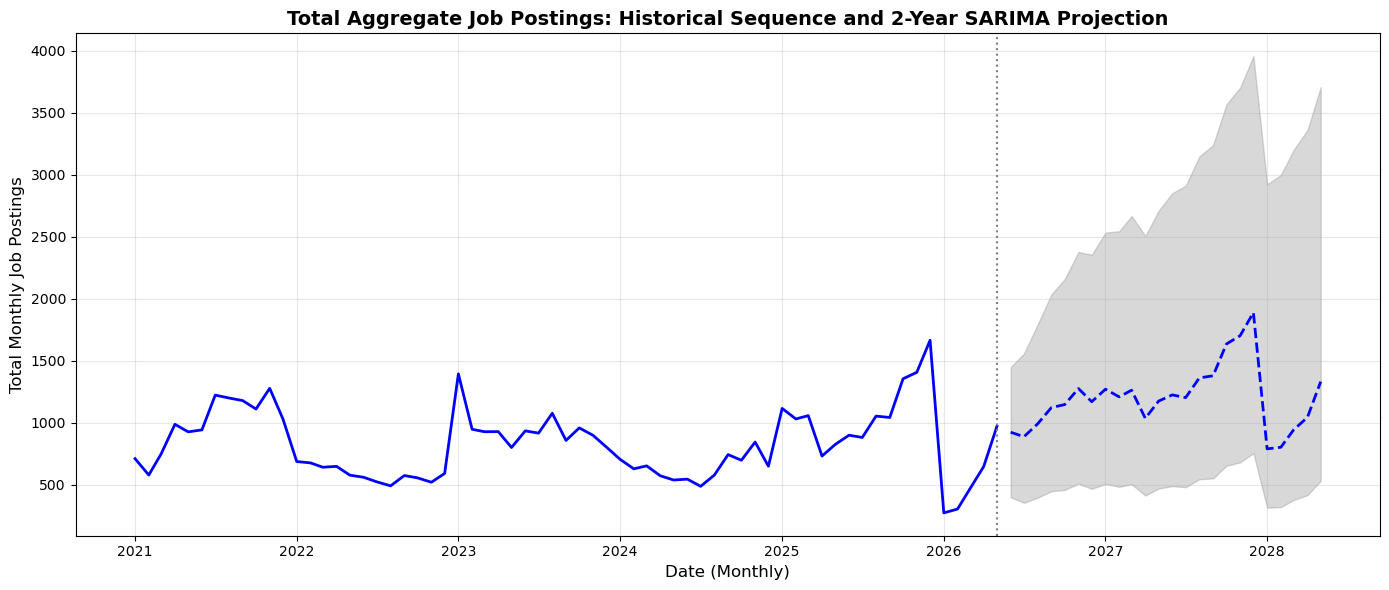

In [16]:
plt.figure(figsize=(14, 6))

#full historical data
plt.plot(y_full.index, y_full, label='Historical Postings (All Jobs)', color='blue', linewidth=2)
#2-year future forecast plot
plt.plot(two_year_forecast_sarimax.index, two_year_forecast_sarimax['Forecasted_Postings'],
         label='2-Year SARIMAX Forecast', color='blue', linestyle='--', linewidth=2)

# 95% confidence interval boundary
plt.fill_between(
    two_year_forecast_sarimax.index,
    two_year_forecast_sarimax['Lower_95_CI'],
    two_year_forecast_sarimax['Upper_95_CI'],
    color='grey',
    alpha=0.3,
    label='95% Confidence Interval'
)

plt.axvline(x=y_full.index[-1], color='gray', linestyle=':', label='Forecast Origin')
plt.title('Total Aggregate Job Postings: Historical Sequence and 2-Year SARIMA Projection', fontsize=14, fontweight='bold')
plt.xlabel('Date (Monthly)', fontsize=12)
plt.ylabel('Total Monthly Job Postings', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()